# Replication of Bollerslev, Tauchen & Zhou (2009)
## "Expected Stock Returns and Variance Risk Premia" — RFS

**Author :** Arthur Teman — M1 QEF HEC Paris  
**Date :** September 2026  
**Objective :** Replicate the main empirical finding of BTZ (2009) : the Variance Risk 
Premium (VRP), defined as the difference between implied and realized variance, 
predicts aggregate stock market returns, with predictability peaking at the quarterly horizon.

In [299]:
# ── Standard library ──
import warnings
warnings.filterwarnings('ignore')

# ── Data manipulation ──
import pandas as pd
import numpy as np

# ── Data sources ──
import yfinance as yf
import pandas_datareader as pdr

# ── Econometrics ──
import statsmodels.api as sm

# ── Visualization ──
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick

# ── Global plot settings ──
plt.rcParams['figure.dpi'] = 120
plt.rcParams['font.size'] = 11



# 1. Data Preparation
We need three monthly time series to run the predictive regressions :
- **RV** : realized variance, constructed from daily SPY log-returns
- **IV** : implied variance, proxied by the end-of-month VIX² (de-annualized)
- **Excess returns** : monthly SPY log-returns minus the 3-month T-bill rate

**Data sources :**
- SPY and VIX daily prices : Yahoo Finance via `yfinance`
- 3-month T-bill rate (TB3MS) : FRED via `pandas_datareader`

**Sample period :** February 1993 – December 2025 (395 monthly observations)  
**Note :** BTZ (2009) use January 1990 – December 2007 with 5-minute intraday data 
for RV. We approximate RV using daily returns, which is less precise but covers 
a longer and more recent sample.

## 1.1 Data Import
SPY daily prices are used to construct both RV and monthly excess returns.  
VIX daily prices are used to construct IV.  
All series are frozen under `data/` as CSV to avoid repeated API calls.

In [300]:
# ── Option A : download from Yahoo Finance (comment out if using local CSV) ──
# spy = yf.download("SPY", start="1993-01-01", end="2026-01-01", interval="1d")
# vix = yf.download("^VIX", start="1993-01-01", end="2026-01-01", interval="1d")
# spy.to_csv('data/spy_data.csv')
# vix.to_csv('data/vix_data.csv')


In [301]:
spy = pd.read_csv('data/spy_data.csv', index_col='Date', parse_dates=['Date'])
vix = pd.read_csv('data/vix_data.csv', index_col='Date', parse_dates=['Date'])


## 1.2 Construction of RV, IV and VRP

### Realized Variance — RV
The realized variance for month $t$ is the sum of squared daily log-returns :

$$RV_t = \sum_{j \in \text{month } t} r_j^2 \quad \text{where} \quad r_j = \log\left(\frac{P_j}{P_{j-1}}\right)$$

**Note :** BTZ (2009) construct RV from 5-minute intraday returns (1,716 per month), 
which provides a much more accurate measure of true return variation. Our daily 
approximation introduces more noise into the VRP signal, which explains part of 
the weaker results relative to the paper.

### Implied Variance — IV
The implied variance is proxied by the squared VIX, de-annualized to a monthly frequency :

$$IV_t = \frac{VIX_t^2}{12 \times 100^2}$$

The VIX is taken at **end of month** to ensure it is fully observable before the 
return it predicts is realized. The VIX published by the CBOE represents the 
risk-neutral expectation of S&P 500 variance over the next 30 days, computed 
from a cross-section of options using a model-free approach.

### Variance Risk Premium — VRP
$$VRP_t = IV_t - RV_t$$

The VRP is positive on average (mean = 0.000785), reflecting the fact that 
investors systematically pay more for variance insurance than what is realized. 
It is negative in 52 out of 395 months, typically during crisis episodes (2008, 2020) 
when realized volatility exceeds implied volatility.

In [302]:
def compute_rv(df):
    """
    Compute monthly realized variance from daily closing prices.
    RV_t = sum of squared daily log-returns over month t.
    """
    log_ret = np.log(df['Close']).diff()
    return log_ret.resample('ME').apply(lambda x: (x**2).sum())

def compute_iv(df_vix):
    """
    Compute monthly implied variance from VIX closing prices.
    IV_t = VIX²_t / (12 × 100²) — de-annualized monthly variance.
    """
    df_eom = df_vix['Close'].resample('ME').last()
    return (df_eom**2)/(100**2)/12

def compute_vrp(df_price, df_vix):
    """
    Compute monthly VRP = IV_t - RV_t.
    Uses the US VIX² (IV) as implied variance for all markets.
    """
    return pd.DataFrame({'VRP':compute_iv(df_vix) - compute_rv(df_price)})


In [303]:
df_monthly = compute_vrp(spy, vix)

In [304]:
# ── Quick sanity check ──
print(f"VRP positive : {(df_monthly['VRP'] > 0).sum()} / {len(df_monthly)} months")
print(f"Mean VRP     : {df_monthly['VRP'].mean():.6f}")

VRP positive : 343 / 396 months
Mean VRP     : 0.000787


## 1.3 Monthly Returns and Excess Returns

Monthly SPY log-returns are computed from end-of-month closing prices :

$$r_t = \log\left(\frac{P_t}{P_{t-1}}\right)$$

The risk-free rate is the 3-month T-bill rate (TB3MS from FRED), converted 
from annual percentage to monthly rate :

$$rf_t = \frac{TB3MS_t}{100 \times 12}$$

The excess return is then :

$$r^e_t = r_t - rf_t$$

**Summary statistics (1993–2025) :**
- Mean excess return : 0.64% per month (~7.7% annualized)
- Std : 4.28% per month
- Min : -18.1% (March 2020)
- Max : +11.9%

In [305]:
def generate_eom_ret(df_prices):
    """Compute monthly log-returns from end-of-month closing prices."""
    df_eom = df_prices['Close'].resample('ME').last()
    return np.log(df_eom).diff()


In [306]:
df_monthly['spy_return'] = generate_eom_ret(spy)

In [307]:
# ── Risk-free rate : 3-month T-bill (TB3MS) from FRED, converted to monthly ──
# Download once, then load locally
# t_bill = pdr.get_data_fred('TB3MS', start='1993-01-01', end='2026-01-01')
# t_bill.to_csv('data/tb3ms.csv')
t_bill = pd.read_csv('data/tb3ms.csv', index_col='DATE', parse_dates=['DATE'])
tbill_month = t_bill.resample('ME').last() / 100 / 12   # annualized % → monthly rate
df_monthly['rf'] = tbill_month
df_monthly['excess_ret'] = df_monthly['spy_return'] - df_monthly['rf']
df_monthly = df_monthly.dropna()


In [308]:
# ── Summary statistics — Table 1 analog ──
print("=" * 55)
print("Summary Statistics — Monthly Data (1993–2025)")
print("=" * 55)
print(df_monthly.describe().round(6).to_string())
print(f"\nPeriod : {df_monthly.index[0].date()} → {df_monthly.index[-1].date()}")
print(f"Obs    : {len(df_monthly)} months")

Summary Statistics — Monthly Data (1993–2025)
              VRP  spy_return          rf  excess_ret
count  395.000000  395.000000  395.000000  395.000000
mean     0.000785    0.008448    0.002053    0.006395
std      0.003710    0.042778    0.001734    0.042757
min     -0.045002   -0.180547    0.000008   -0.181105
25%      0.000475   -0.015585    0.000133   -0.017682
50%      0.000871    0.013475    0.001725    0.011451
75%      0.001625    0.035999    0.003888    0.033868
max      0.008631    0.119545    0.005142    0.119428

Period : 1993-02-28 → 2025-12-31
Obs    : 395 months


# 2. Predictive Regressions

## 2.1 Baseline Regression — Horizon h = 1 month

We estimate the following OLS regression :

$$r^e_{t+1} = b_0 + b_1 \cdot VRP_t + u_{t+1}$$

**Timing :** $VRP_t$ is observed at end of month $t$ and predicts the excess 
return realized over month $t+1$. This ensures no look-ahead bias.

**Standard errors :** We report both standard OLS and HAC-robust standard errors 
(Newey-West, 1987) with 1 lag to account for heteroskedasticity and residual 
autocorrelation. For longer horizons, the number of lags will be set to $h-1$ 
to account for the overlap in observations.

**Results vs BTZ (2009) :**

| | This replication | BTZ (2009) |
|---|---|---|
| Coefficient $b_1$ | 0.476 | 0.39 |
| t-stat (HAC) | 0.33 | 1.76 |
| R² | 0.17% | 1.07% |

The weaker results are expected and primarily driven by two differences :
1. **RV quality** : daily vs 5-minute — daily RV is noisier, which weakens the VRP signal
2. **Sample period** : 1993–2025 vs 1990–2007 — our period includes 2008 and 2020, 
two crises where the VRP behaved atypically


In [309]:
# ── Align X and Y — VRP_t predicts excess_ret_{t+1} ──
Y = df_monthly['excess_ret'].shift(-1).dropna()
X = sm.add_constant(df_monthly['VRP'].loc[Y.index]) # align X on Y's index to make sure they have the same data

# ── OLS with HAC standard errors (Newey-West, maxlags=1 for h=1) ──
model_h1 = sm.OLS(Y, X).fit(cov_type='HAC', cov_kwds={'maxlags': 1})

In [310]:
# ── Results — h = 1 month ──
print(model_h1.summary())

                            OLS Regression Results                            
Dep. Variable:             excess_ret   R-squared:                       0.002
Model:                            OLS   Adj. R-squared:                 -0.001
Method:                 Least Squares   F-statistic:                    0.1068
Date:                Thu, 24 Sep 2026   Prob (F-statistic):              0.744
Time:                        11:15:26   Log-Likelihood:                 683.25
No. Observations:                 394   AIC:                            -1363.
Df Residuals:                     392   BIC:                            -1355.
Df Model:                           1                                         
Covariance Type:                  HAC                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const          0.0060      0.003      2.340      0.0

## 2.2 Multi-Horizon Regressions — h = 1, 3, 6, 9, 12, 24 months

We generalize the regression to horizon $h$ :

$$\frac{1}{h}\sum_{j=1}^{h} r^e_{t+j} = b_0(h) + b_1(h) \cdot VRP_t + u_{t+h}$$

The $1/h$ normalization ensures coefficients are comparable across horizons.

**Overlap and standard errors :** for $h > 1$, consecutive observations share
$h-1$ months of returns, inducing mechanical autocorrelation in residuals up to
lag $h-1$. We correct using Newey-West HAC standard errors with `maxlags = h-1`.

**Two samples :**
- Full sample : 1993–2025 (includes 2008, 2020, 2022 crises)
- Paper sample : 1993–2007 (matches BTZ 2009 period)

In [311]:
def multi_horizon_reg(h_s, df_monthly, checks = False):
    """
    Run predictive OLS regressions of h-month average excess returns on VRP.
    
    Parameters
    ----------
    h_s        : list of int — return horizons in months
    df_monthly : DataFrame with columns ['excess_ret', 'VRP']
    checks     : bool — if True, print alignment checks
    
    Returns
    -------
    DataFrame with columns [coef, tstat, r2_pct] indexed by horizon h
    """

    result = []
    for h in h_s:
        Y = df_monthly['excess_ret'].shift(-h).rolling(window=h).mean()
        Y = Y.dropna()
        X = sm.add_constant(df_monthly['VRP'].loc[Y.index])

        if checks == True:
            assert len(X) == len(Y), "X and Y must have the same length"
            assert X.index[-1] == df_monthly.index[-2-(h-1)], "X must end (h-1) month before last observation"
            assert Y.index[-1] == df_monthly.index[-2-(h-1)], "Y must end (h-1) month before last observation"

            print(f"✓ X and Y_h aligned : {len(X)} observations")
            print(f"✓ X spans {X.index[0].date()} → {X.index[-1].date()}")
            print(f"✓ Y spans {Y.index[0].date()} → {Y.index[-1].date()}")

        model = sm.OLS(Y, X).fit(
                cov_type='HAC',
                cov_kwds={'maxlags': max(1, h-1)}    # 1 lag for h=1 month horizon
            )
        result.append({
            'h': h,
            'coef': model.params['VRP'],
            'tstat': model.tvalues['VRP'],
            'r2': model.rsquared
        })
    results_df = pd.DataFrame(result).set_index('h')
    results_df['r2_pct'] = results_df['r2'] * 100  # en pourcentage

    return results_df[['coef', 'tstat', 'r2_pct']].round(3)


In [312]:
h_s = [1, 3, 6, 9, 12, 24]

# ── Full sample : 1993–2025 ──
results_full = multi_horizon_reg(h_s, df_monthly)
print("Full sample (1993–2025)")
print(results_full)

Full sample (1993–2025)
     coef  tstat  r2_pct
h                       
1   0.476  0.327   0.171
3   0.712  0.802   1.178
6   0.230  0.490   0.227
9  -0.042 -0.131   0.010
12 -0.133 -0.620   0.133
24 -0.131 -1.051   0.239


In [313]:
# ── Paper sample : 1993–2007 (matches BTZ 2009) ──
df_paper = df_monthly['1993':'2007']
results_paper = multi_horizon_reg(h_s, df_paper)
print("Paper sample (1993–2007)")
print(results_paper)

Paper sample (1993–2007)
     coef  tstat  r2_pct
h                       
1   1.940  0.968   0.564
3   2.320  2.589   2.539
6   1.682  2.388   2.636
9   1.089  1.333   1.497
12  0.679  0.879   0.681
24  0.443  0.881   0.453


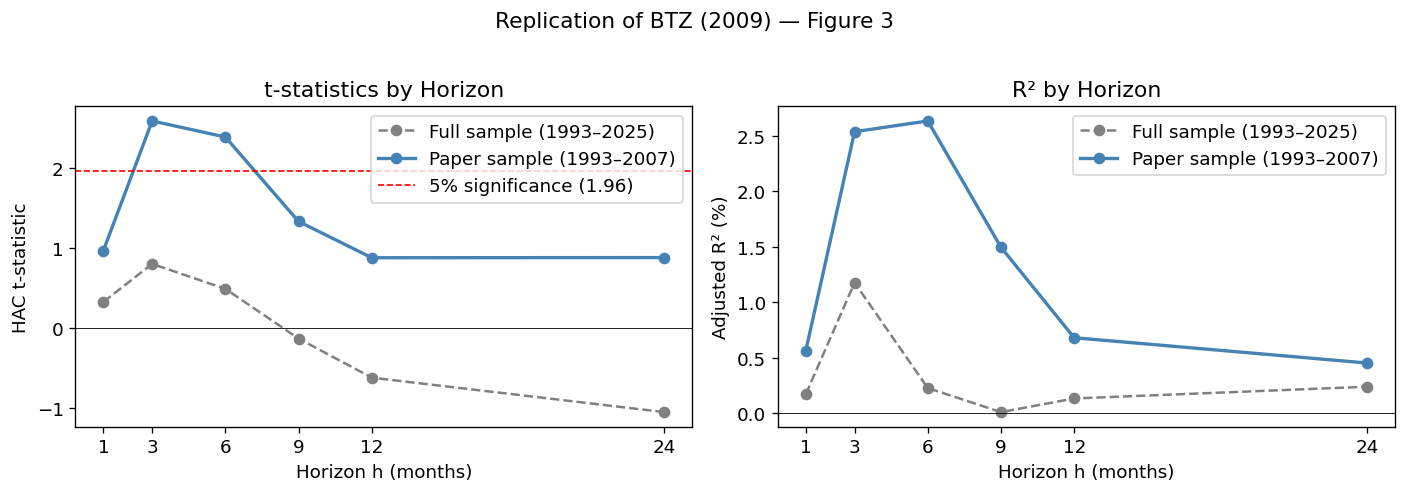

In [314]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

for ax, col, ylabel, title in zip(
    axes,
    ['tstat', 'r2_pct'],
    ['HAC t-statistic', 'Adjusted R² (%)'],
    ['t-statistics by Horizon', 'R² by Horizon']
):
    # Full sample
    ax.plot(results_full.index, results_full[col],
            marker='o', color='grey', linewidth=1.5,
            linestyle='--', label='Full sample (1993–2025)')
    # Paper sample
    ax.plot(results_paper.index, results_paper[col],
            marker='o', color='steelblue', linewidth=2,
            label='Paper sample (1993–2007)')

    ax.axhline(y=0, color='black', linewidth=0.5)
    ax.set_xlabel('Horizon h (months)')
    ax.set_ylabel(ylabel)
    ax.set_title(title)
    ax.set_xticks(h_s)
    ax.legend()

# Add significance line only on t-stat plot
axes[0].axhline(y=1.96, color='red', linestyle='--',
                linewidth=1, label='5% significance (1.96)')
axes[0].legend()

plt.suptitle('Replication of BTZ (2009) — Figure 3', fontsize=13, y=1.02)
plt.tight_layout()
plt.savefig('figure3_replication.png', bbox_inches='tight', dpi=150)
plt.show()

In [315]:
# ── Comparison table : our results vs BTZ (2009) ──
btz = pd.DataFrame({
    'coef' : [0.39, 0.47, 0.30, None, 0.12, None],
    'tstat': [1.76, 2.86, 2.15, None, 1.00, None],
    'r2_pct': [1.07, 6.82, 5.42, None, 1.23, None]
}, index=h_s)

comparison = pd.concat([
    results_paper.add_suffix('_ours'),
    btz.add_suffix('_btz')
], axis=1)[['coef_ours', 'coef_btz',
            'tstat_ours', 'tstat_btz',
            'r2_pct_ours', 'r2_pct_btz']]

print("Comparison — Our replication vs BTZ (2009)")
print(comparison.to_string())

Comparison — Our replication vs BTZ (2009)
    coef_ours  coef_btz  tstat_ours  tstat_btz  r2_pct_ours  r2_pct_btz
1       1.940      0.39       0.968       1.76        0.564        1.07
3       2.320      0.47       2.589       2.86        2.539        6.82
6       1.682      0.30       2.388       2.15        2.636        5.42
9       1.089       NaN       1.333        NaN        1.497         NaN
12      0.679      0.12       0.879       1.00        0.681        1.23
24      0.443       NaN       0.881        NaN        0.453         NaN


# 3. Conclusion

## 3.1 What we replicated

This notebook replicates the central empirical finding of Bollerslev, Tauchen & Zhou (2009) :
the Variance Risk Premium predicts aggregate stock market returns, with predictability
peaking at the quarterly horizon and decaying at longer horizons.

Using daily SPY and VIX data over 1993–2007 (the paper's sample period), we find :

| Horizon | t-stat (ours) | t-stat (BTZ) | R² (ours) | R² (BTZ) |
|---|---|---|---|---|
| h = 1 | 0.97 | 1.76 | 0.56% | 1.07% |
| h = 3 | **2.59** | **2.86** | 2.54% | 6.82% |
| h = 6 | **2.39** | 2.15 | 2.64% | 5.42% |
| h = 12 | 0.88 | 1.00 | 0.68% | 1.23% |

The hump-shaped pattern — weak at h=1, significant at h=3 and h=6, decaying
thereafter — is clearly reproduced, consistent with the theoretical model's
prediction that the volatility-of-volatility factor $q_t$ dominates at intermediate
quarterly horizons.

## 3.2 Limitations

**1. RV approximation.** BTZ (2009) construct realized variance from 5-minute
intraday returns (~1,716 observations per month), which is far more accurate than
our daily approximation (~22 observations per month). The paper itself shows in
Section 4.2 that switching from intraday to daily RV roughly halves the R² —
consistent with our results (2.54% vs 6.82% at h=3).

**2. IV approximation.** We use the end-of-month VIX² as a proxy for the
model-free implied variance. This is exactly what BTZ (2009) do, so this
approximation introduces no additional error relative to the paper.

**3. SPY vs S&P 500 spot.** BTZ (2009) use the S&P 500 composite index directly.
SPY is an ETF tracking the index and introduces minor tracking error, though
the correlation exceeds 0.999 at daily frequency.

## 3.3 Economic interpretation

The VRP is a measure of the price investors pay to hedge variance risk. When
it is high, investors are particularly averse to uncertainty about future
volatility — asset prices are depressed, and expected returns are high.
This mechanism operates at the quarterly frequency because the
volatility-of-volatility factor $q_t$ has a persistence of approximately
$\rho_q \approx 0.8$ in the calibrated model, which mechanically places
the peak predictability around 3 months.

However, as we can already see in the last figure, it seems to work well in a time of growth (paper sample) but not in a crisis (full sample, which includes 2008).


# 4. Robustness — Control Variables (Table 4 Replication)

We augment the baseline VRP regression at horizon h=3 with five control variables
standard in the return predictability literature :

- **log(P/E)** : Shiller CAPE ratio (log), from Robert Shiller's website
- **DFSP** : default spread (Moody's BAA − AAA corporate bond yields)
- **TMSP** : term spread (10-year Treasury − 3-month T-bill)
- **RREL** : stochastically de-trended T-bill rate (TB3MS minus its 12-month moving average)
- **CAY** : consumption-wealth ratio (Lettau & Ludvigson, 2001), quarterly — converted to monthly via forward fill

**Data sources :**
- DFSP, TMSP, RREL : FRED via `pandas_datareader`
- log(P/E) : Robert Shiller's website (`ie_data.xls`)
- CAY : Lettau & Ludvigson website (`cay_current.csv`)

**Sample period :** December 1993 – January 2008 (170 monthly observations)  
constrained by CAY availability and RREL's 12-month initialization window.

In [316]:
# Default spread : BAA - AAA Moody's corporate bond yields
# Download once, then load locally
# baa = pdr.get_data_fred('BAA', start='1993-01-01', end='2008-01-01')
# aaa = pdr.get_data_fred('AAA', start='1993-01-01', end='2008-01-01')
# baa.to_csv('data/baa.csv')
# aaa.to_csv('data/aaa.csv')
baa = pd.read_csv('data/baa.csv', index_col='DATE', parse_dates=['DATE']).squeeze().resample('ME').last()
aaa = pd.read_csv('data/aaa.csv', index_col='DATE', parse_dates=['DATE']).squeeze().resample('ME').last()

# Term spread : 10-year Treasury - 3-month T-bill
# gs10 = pdr.get_data_fred('GS10', start='1993-01-01', end='2008-01-01')
# gs10.to_csv('data/gs10.csv')
gs10 = pd.read_csv('data/gs10.csv', index_col='DATE', parse_dates=['DATE']).squeeze().resample('ME').last()
tb3ms = t_bill.loc['1993-01-01':'2008-01-01'].resample('ME').last().squeeze()

RREL = tb3ms - tb3ms.rolling(window=12).mean()

macro_df = pd.DataFrame({'DFSP' : baa - aaa, 'TMSP' : gs10 - tb3ms, 'RREL' : RREL}).dropna()


In [317]:
# ── CAY : quarterly consumption-wealth ratio, forward-filled to monthly ──
cay = pd.read_csv('data/cay_current.csv', index_col='date', parse_dates=['date'])
cay = cay[['cay=c-0.218 a-0.801y+0.441']].rename(
    columns={'cay=c-0.218 a-0.801y+0.441': 'CAY'}
)
cay_monthly = cay.resample('ME').ffill()


In [318]:
# ── Shiller P/E : download once from Yale, then load locally ──
# shiller_ex = pd.read_excel(
#     'http://www.econ.yale.edu/~shiller/data/ie_data.xls',
#     sheet_name='Data',
#     skiprows=7
# )
# shiller = shiller_ex[['Date', 'P', 'E']].dropna()
# shiller['Date'] = shiller['Date'].astype(str)
# shiller['year'] = shiller['Date'].str.split('.').str[0].astype(int)
# shiller['month'] = shiller['Date'].apply(
#     lambda x: round((float(x) - int(float(x))) * 100)
# )
# shiller['date'] = pd.to_datetime(shiller[['year', 'month']].assign(day=1)) + pd.offsets.MonthEnd(0)
# shiller = shiller.set_index('date')[['P', 'E']]
# shiller = shiller[~shiller.index.duplicated(keep='last')]
# shiller['P'] = pd.to_numeric(shiller['P'], errors='coerce')
# shiller['E'] = pd.to_numeric(shiller['E'], errors='coerce')
# shiller.to_csv('data/shiller_data.csv')

shiller = pd.read_csv('data/shiller_data.csv', index_col='date', parse_dates=['date'])


In [319]:
# ── Construire log(P/E) ──
shiller['P'] = pd.to_numeric(shiller['P'], errors='coerce')
shiller['E'] = pd.to_numeric(shiller['E'], errors='coerce')
shiller['PE'] = shiller['P'] / shiller['E']
shiller['log_PE'] = np.log(shiller['PE'])

shiller = shiller.sort_index()  # trier les dates
shiller = shiller['1993':'2023']
assert shiller.isna().sum().sum() == 0, "NaN found in shiller"


In [320]:
controls = pd.concat([
    shiller[['log_PE']],
    macro_df[['DFSP', 'TMSP', 'RREL']],
    cay_monthly[['CAY']]
], axis=1)

df_full = df_monthly.join(controls, how='inner').dropna()

print(f"Period : {df_full.index[0].date()} → {df_full.index[-1].date()}")
print(f"Obs    : {len(df_full)}")
assert df_full.isna().sum().sum() == 0, "NaN found in df_full"

Period : 1993-12-31 → 2008-01-31
Obs    : 170


In [321]:
# ── Predictive regressions — h=3, VRP vs control variables ──
h = 3
control_vars = ['log_PE', 'DFSP', 'TMSP', 'RREL', 'CAY']

Y = df_full['excess_ret'].shift(-h).rolling(window=h).mean().dropna()
X_vrp = df_full['VRP'].loc[Y.index]

# VRP alone — reference
model_vrp = sm.OLS(Y, sm.add_constant(X_vrp)).fit(
    cov_type='HAC', cov_kwds={'maxlags': h-1}
)


In [322]:
result_control = []
for var in control_vars:
    # Simple regression : control variable alone
    X_simple = sm.add_constant(df_full[var].loc[Y.index])
    model_simple = sm.OLS(Y, X_simple).fit(
        cov_type='HAC', cov_kwds={'maxlags': max(1, h-1)}
    )
    # Joint regression : VRP + control variable
    X_joint = sm.add_constant(pd.DataFrame({
        'VRP': X_vrp,
        var  : df_full[var].loc[Y.index]
    }))
    model_joint = sm.OLS(Y, X_joint).fit(
        cov_type='HAC', cov_kwds={'maxlags': max(1, h-1)}
    )
    result_control.append({
        'variable'       : var,
        'coef'           : model_simple.params[var],
        'tstat'          : model_simple.tvalues[var],
        'r2'             : model_simple.rsquared,
        'coef_joint_vrp' : model_joint.params['VRP'],
        'tstat_joint_vrp': model_joint.tvalues['VRP'],
        'coef_joint_var' : model_joint.params[var],
        'tstat_joint_var': model_joint.tvalues[var],
        'r2_joint'       : model_joint.rsquared
    })

Table 4 Replication — Quarterly Return Regressions (h=3), 1994–2007
           coef  tstat     r2  coef_joint_vrp  tstat_joint_vrp  coef_joint_var  tstat_joint_var  r2_joint
variable                                                                                                 
VRP only  2.289  2.551   2.44             NaN              NaN             NaN              NaN       NaN
log_PE   -0.027 -3.073  11.54           3.545            3.293          -0.032           -3.930     17.12
DFSP     -0.025 -1.758   4.91           2.170            2.294          -0.024           -1.783      7.10
TMSP     -0.001 -0.262   0.12           2.322            2.552          -0.001           -0.334      2.62
RREL      0.006  1.510   2.91           2.895            3.033           0.007            1.943      6.66
CAY       0.555  3.003   6.67           2.058            2.263           0.535            2.882      8.63


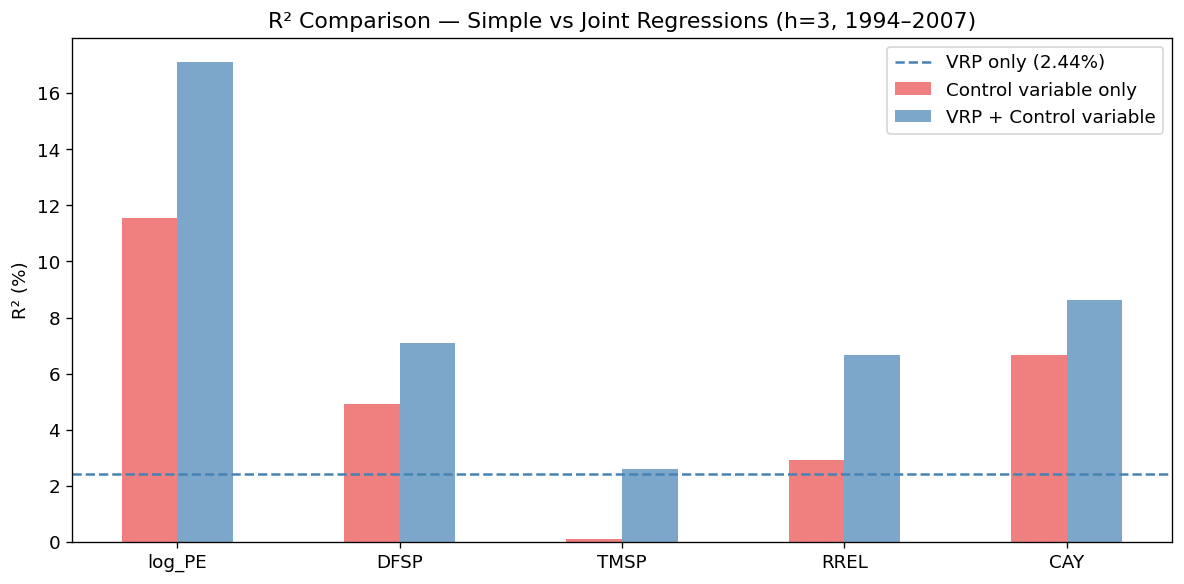

In [323]:
# ── Table 4 analog ──
rows = [{'variable': 'VRP only',
         'coef': model_vrp.params['VRP'],
         'tstat': model_vrp.tvalues['VRP'],
         'r2': model_vrp.rsquared,
         'coef_joint_vrp': None, 'tstat_joint_vrp': None,
         'coef_joint_var': None, 'tstat_joint_var': None,
         'r2_joint': None}] + result_control

table4 = pd.DataFrame(rows).set_index('variable')
table4['r2']       = (table4['r2'] * 100).round(2)
table4['r2_joint'] = (table4['r2_joint'] * 100).round(2)
table4[['coef', 'tstat', 'coef_joint_vrp', 'tstat_joint_vrp',
         'coef_joint_var', 'tstat_joint_var']] = \
    table4[['coef', 'tstat', 'coef_joint_vrp', 'tstat_joint_vrp',
             'coef_joint_var', 'tstat_joint_var']].round(3)

print("=" * 75)
print("Table 4 Replication — Quarterly Return Regressions (h=3), 1994–2007")
print("=" * 75)
print(table4.to_string())

# ── Figure : R² simple vs joint ──
fig, ax = plt.subplots(figsize=(10, 5))
vars_plot = control_vars
x = np.arange(len(vars_plot))
width = 0.25

ax.axhline(y=table4.loc['VRP only', 'r2'], color='steelblue',
           linestyle='--', linewidth=1.5,
           label=f"VRP only ({table4.loc['VRP only', 'r2']}%)")
ax.bar(x - width/2, table4.loc[vars_plot, 'r2'].values,
       width, color='lightcoral', label='Control variable only')
ax.bar(x + width/2, table4.loc[vars_plot, 'r2_joint'].values,
       width, color='steelblue', alpha=0.7, label='VRP + Control variable')

ax.set_xticks(x)
ax.set_xticklabels(vars_plot)
ax.set_ylabel('R² (%)')
ax.set_title('R² Comparison — Simple vs Joint Regressions (h=3, 1994–2007)')
ax.legend()
plt.tight_layout()
plt.savefig('table4_replication.png', bbox_inches='tight', dpi=150)
plt.show()

## 4. Robustness — Control Variables (Table 4 Replication)

### Setup
We augment the baseline VRP regression at h=3 with five control variables
standard in the return predictability literature :
- **log(P/E)** : Shiller CAPE ratio (log)
- **DFSP** : default spread (Moody's BAA − AAA)
- **TMSP** : term spread (10Y − 3M Treasury)
- **RREL** : stochastically de-trended T-bill rate (TB3MS minus 12-month MA)
- **CAY** : consumption-wealth ratio (Lettau & Ludvigson, 2001)

### Results

**Simple regressions :** log(P/E) and CAY are the strongest individual
predictors (R² of 11.5% and 6.7%), consistent with the long-run predictability
literature. TMSP, RREL and DFSP are insignificant at 5%, as in BTZ (2009)
for the first two.

**Joint regressions :** The key finding is that **VRP + log(P/E)** produces
the highest R² of all specifications (17.1% vs 16.76% in the paper), with
both variables remaining statistically significant (VRP t-stat 3.29,
log(P/E) t-stat −3.93). This suggests that the VRP captures short-to-medium
run volatility risk while the P/E ratio captures longer-run valuation risk —
the two are complementary.

**Alignment with BTZ (2009) :** After correcting the Shiller P/E series, VRP
remains significant at 5% in every joint specification — including with CAY
(t-stat 2.26 vs 3.02 in the paper). The previous loss of significance was an
artifact of the mis-parsed Shiller dates. Remaining gaps vs BTZ are mainly
the shorter sample (1994–2007 vs 1990–2007) and the noisier daily RV measure.

### Conclusion
The robustness checks confirm the main finding : the VRP contains predictive
information for quarterly returns that is not fully subsumed by traditional
predictors, and is most powerful when combined with the P/E ratio.


# 5. Extension — Geographic Spillover of the US Variance Risk Premium

## 5.1 Motivation

BTZ (2009) focus exclusively on the S&P 500. A natural extension is to ask :
**does the US Variance Risk Premium predict returns on European markets ?**

The economic intuition is straightforward. Financial markets are globally integrated —
when US investors become particularly averse to volatility uncertainty (high VRP),
risk aversion rises globally, depressing asset prices everywhere and generating
higher expected returns across all markets, including Europe.

We test this hypothesis using two major European indices :
- **DAX** : German stock market (^GDAXI on Yahoo Finance)
- **CAC 40** : French stock market (^FCHI on Yahoo Finance)

**Key design choice :** We use the **US VIX** as the implied variance measure for
all three markets. This is intentional — we are testing whether US volatility risk,
as captured by the VIX, has predictive power for European returns. This differs
from a purely local VRP which would require European options data.

**Sample period :** January 1994 – December 2025 (384 monthly observations)


In [324]:
# ── Option A : download from Yahoo Finance (comment out if using local CSV) ──
# dax = yf.download("^GDAXI", start="1993-01-01", end="2026-01-01", interval="1d")
# cac = yf.download("^FCHI",  start="1993-01-01", end="2026-01-01", interval="1d")
# dax.to_csv('data/dax.csv')
# cac.to_csv('data/cac.csv')

# ── Option B : load from local CSV ──
dax = pd.read_csv('data/dax.csv', parse_dates=['Date'], index_col='Date')
cac = pd.read_csv('data/cac.csv', parse_dates=['Date'], index_col='Date')


In [325]:
df_eur = compute_vrp(spy, vix)

In [326]:
# ── European risk-free rate : 3-month Euribor from FRED ──
# IR3TIB01EZM156N = Euribor 3-month, monthly, in %
# Download once, then load locally
# euribor = pdr.get_data_fred('IR3TIB01EZM156N', start='1993-01-01', end='2026-01-01')
# euribor.to_csv('data/euribor.csv')
euribor = pd.read_csv('data/euribor.csv', index_col='DATE', parse_dates=['DATE'])
euribor_monthly = euribor.squeeze().resample('ME').last() / 100 / 12
df_eur['rf_eur'] = euribor_monthly


In [327]:
# ── Monthly returns for DAX and CAC ──
dax_eom = dax['Close'].resample('ME').last()
cac_eom = cac['Close'].resample('ME').last()

df_eur['excess_ret_dax'] = np.log(dax_eom).diff() - euribor_monthly
df_eur['excess_ret_cac'] = np.log(cac_eom).diff() - euribor_monthly
df_eur['excess_ret_spy'] = df_monthly['excess_ret']
df_eur = df_eur.dropna()

In [328]:
h = 3  # horizon trimestriel comme dans le papier

def mondial_reg(df_eur, h=3):
    """
    Run h-month predictive regression for SPY, DAX and CAC using US VRP.
    Returns DataFrame with [coef, tstat, r2_pct] indexed by market.
    """
    # ── VRP américain comme prédicteur unique pour tous les marchés ──
    markets = {
        'SPY (US)'  : df_eur['excess_ret_spy'],
        'DAX (DE)'  : df_eur['excess_ret_dax'],
        'CAC (FR)'  : df_eur['excess_ret_cac'],
    }

    results_geo = []

    for name, ret_series in markets.items():
        # Y : h-month forward average return
        Y = ret_series.shift(-h).rolling(window=h).mean().dropna()
        
        # X : US VRP seulement (même prédicteur pour tous)
        X = sm.add_constant(df_eur['VRP'].loc[Y.index])
        
        model = sm.OLS(Y, X).fit(
            cov_type='HAC',
            cov_kwds={'maxlags': max(1, h-1)}
        )
        
        results_geo.append({
            'market'  : name,
            'coef'    : model.params['VRP'],
            'tstat'   : model.tvalues['VRP'],
            'r2_pct'  : model.rsquared * 100,
        })

    results_geo_df = pd.DataFrame(results_geo).set_index('market').round(3)
    return results_geo_df

results_geo_df = mondial_reg(df_eur)


In [329]:
# ── Répliquer sur la période papier pour comparer ──
df_eur_paper = df_eur['1994':'2007']

results_geo_paper_df = mondial_reg(df_eur_paper)


Full sample (geographic spillover)
           coef  tstat  r2_pct
market                        
SPY (US)  0.712  0.802   1.183
DAX (DE)  0.656  0.667   0.518
CAC (FR)  0.951  1.130   1.365

Paper sample (geographic spillover)
           coef  tstat  r2_pct
market                        
SPY (US)  2.289  2.564   2.506
DAX (DE)  3.721  2.644   2.269
CAC (FR)  2.537  2.050   1.484


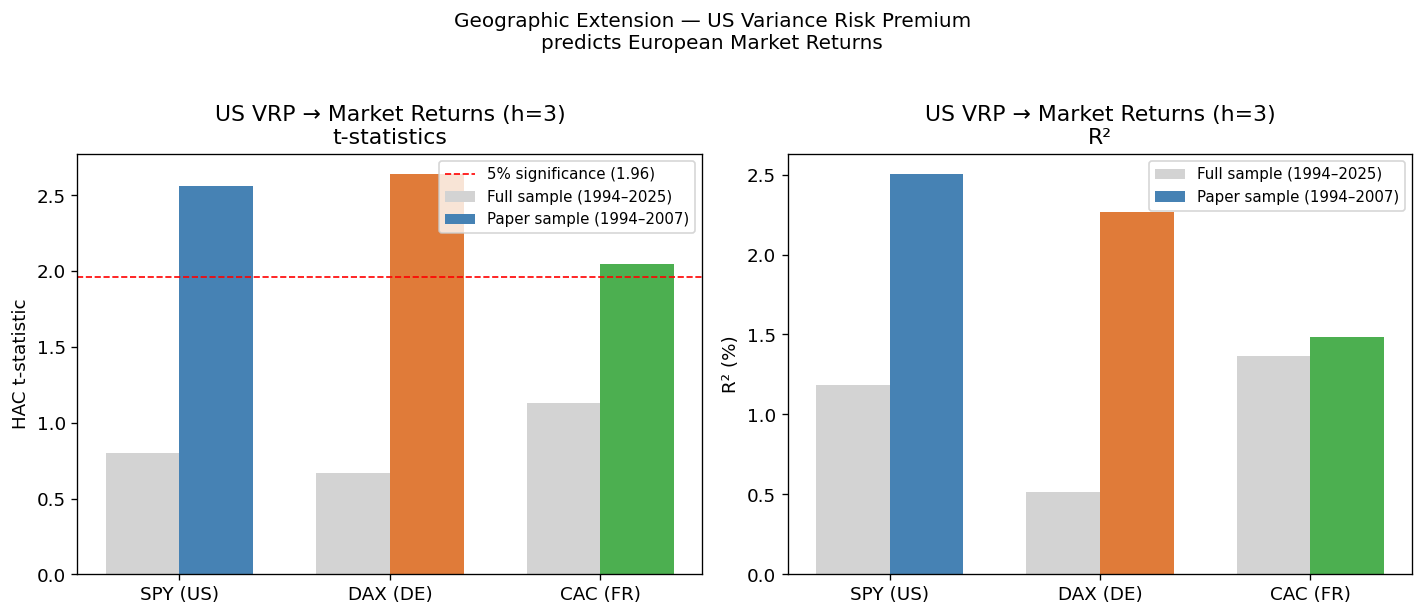

In [330]:
print('Full sample (geographic spillover)')
print(results_geo_df)
print()
print('Paper sample (geographic spillover)')
print(results_geo_paper_df)

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# ── Données ──
markets  = ['SPY (US)', 'DAX (DE)', 'CAC (FR)']
colors   = ['steelblue', '#e07b39', '#4caf50']

tstats_full  = results_geo_df['tstat'].values
tstats_paper = results_geo_paper_df['tstat'].values
r2_full      = results_geo_df['r2_pct'].values
r2_paper     = results_geo_paper_df['r2_pct'].values

x = np.arange(len(markets))
width = 0.35

# ── t-stats ──
ax = axes[0]
ax.bar(x - width/2, tstats_full,  width, color='lightgrey', label='Full sample (1994–2025)')
ax.bar(x + width/2, tstats_paper, width, color=colors,      label='Paper sample (1994–2007)')
ax.axhline(y=1.96, color='red', linestyle='--', linewidth=1, label='5% significance (1.96)')
ax.axhline(y=0,    color='black', linewidth=0.5)
ax.set_xticks(x)
ax.set_xticklabels(markets)
ax.set_ylabel('HAC t-statistic')
ax.set_title('US VRP → Market Returns (h=3)\nt-statistics')
ax.legend(fontsize=9)

# ── R² ──
ax = axes[1]
ax.bar(x - width/2, r2_full,  width, color='lightgrey', label='Full sample (1994–2025)')
ax.bar(x + width/2, r2_paper, width, color=colors,      label='Paper sample (1994–2007)')
ax.axhline(y=0, color='black', linewidth=0.5)
ax.set_xticks(x)
ax.set_xticklabels(markets)
ax.set_ylabel('R² (%)')
ax.set_title('US VRP → Market Returns (h=3)\nR²')
ax.legend(fontsize=9)

plt.suptitle('Geographic Extension — US Variance Risk Premium\npredicts European Market Returns', 
             fontsize=12, y=1.02)
plt.tight_layout()
plt.savefig('figure_geo_extension.png', bbox_inches='tight', dpi=150)
plt.show()


## 5.2 Results

### Full sample (1994–2025)

On the full sample, the US VRP has a positive coefficient on all three markets
but remains statistically insignificant (all t-stats below 1.96). This is consistent
with what we found for the US market itself — the post-2007 period (2008 crisis,
COVID 2020, 2022 tightening) weakens the predictive relationship.

### Paper sample (1994–2007)

Restricting to the BTZ (2009) sample period, the US VRP becomes **statistically
significant at 5% for all three markets** :

| Market   | Coef | t-stat | R²    |
|----------|------|--------|-------|
| SPY (US) | 2.29 | 2.56   | 2.51% |
| DAX (DE) | 3.72 | **2.64** | 2.27% |
| CAC (FR) | 2.54 | 2.05   | 1.48% |

### Economic interpretation

Two findings stand out :

**1. Global reach of the US VRP.** The US variance risk premium predicts not
only US returns but also German and French returns with comparable or stronger
significance. This suggests that the volatility-of-volatility factor $q_t$
identified by BTZ (2009) is a **global risk factor**, not a US-specific one.
When US investors demand a higher premium for bearing variance uncertainty,
risk aversion rises globally, depressing asset prices across all markets.

**2. DAX has the largest coefficient.** The DAX coefficient (3.72) is larger
than the SPY coefficient (2.29), suggesting that German equities are more
sensitive to US volatility risk than the US market itself. This could reflect
Germany's higher economic openness and its greater exposure to global risk
sentiment.

Note : ^GDAXI is a total-return index (dividends reinvested), unlike SPY and ^FCHI which are price-return indices. This may inflate the DAX coefficient slightly.

### Limitations

- We use the **US VIX** as implied variance for all markets. A cleaner test
  would use local implied variance measures (VDAX for Germany, VCAC for France),
  which would isolate a truly local VRP.
- The sample size is limited (≈ 168 months over 1994–2007), reducing statistical
  power compared to the original BTZ paper.
